## Ejercicio hiperparametrización breast cancer de sklearn

1. Carga el dataset [breast_cancer de `sklearn`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
2. Prueba al menos 5 modelos diferentes de clasificación y aplica un GridSearchCV mediante Pipelines. Aplica también un RandomizedSearchCV.
3. Conclusiones. Guarda el modelo final en un archivo con pickle.

In [3]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

In [4]:
%matplotlib inline
data = load_breast_cancer()
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [5]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [6]:
print(data['DESCR'])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [7]:
df = pd.DataFrame(data['data'], columns=data['feature_names'])
df['target'] = data['target']
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [9]:
# from data_profiling import ProfileReport

# profile = ProfileReport(df, title="Profiling Report")
# profile.to_file("breast_cancer_report.html")

En el informe aparecen 26 alertas que indican que hay correlación entre diferentes features.

<Axes: >

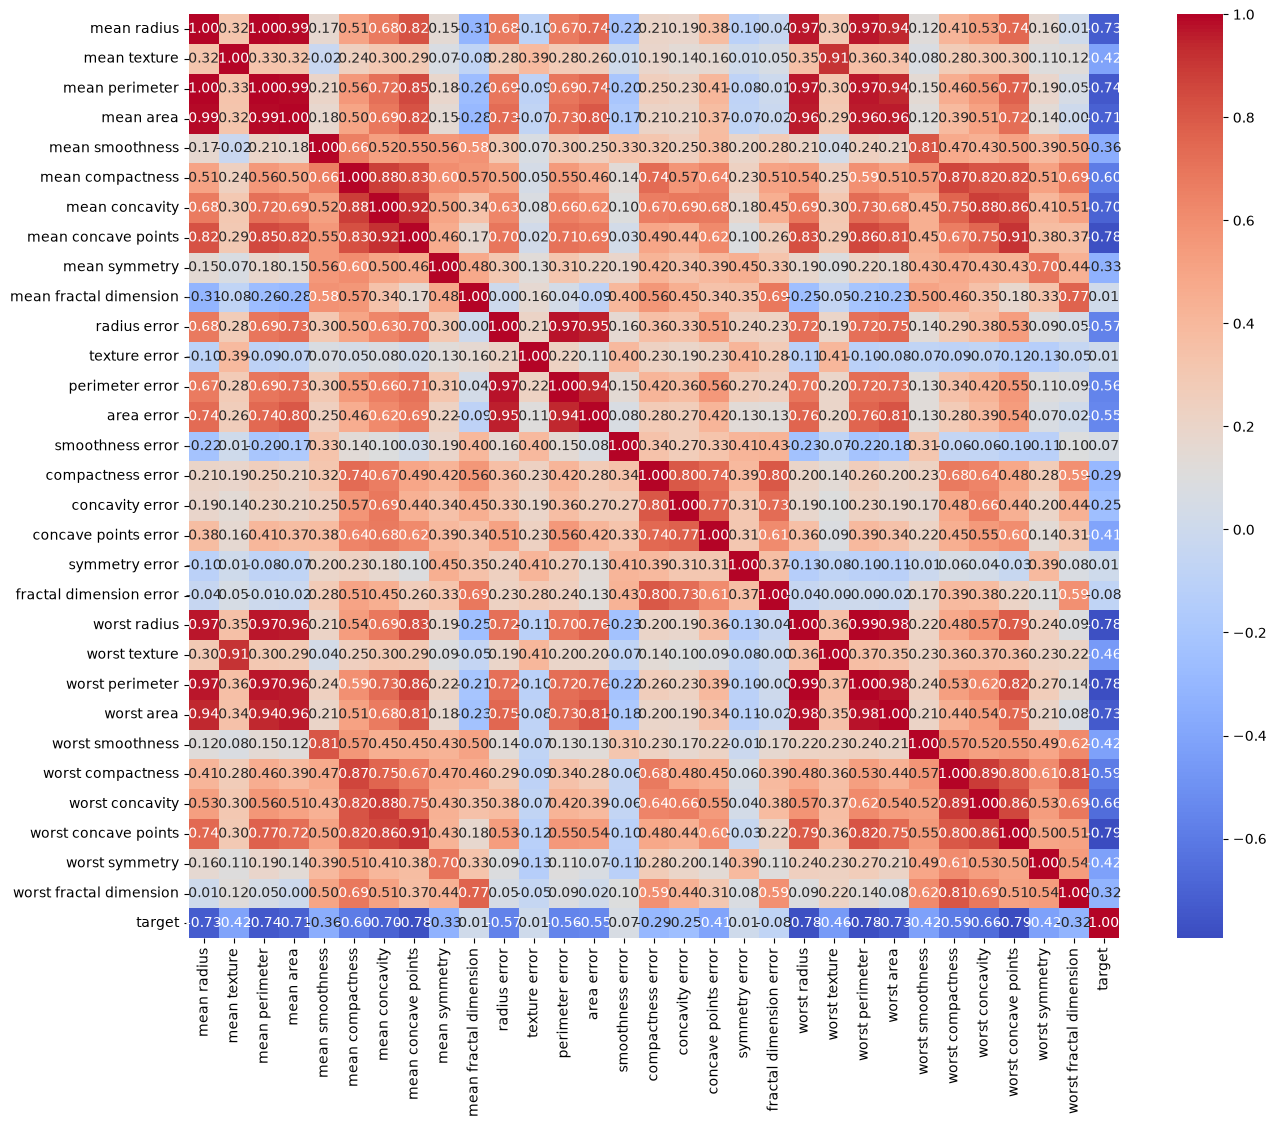

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(df.corr(), cmap="coolwarm", annot=True, fmt=".2f")

In [14]:
corr_matrix = df.corr().abs()

# 2. Quedarnos solo con el triángulo superior (evita duplicados y la diagonal de 1s)
mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
pares = corr_matrix.where(mask).unstack().dropna()

# 3. Ordenar de mayor a menor (en valor absoluto para ver correlaciones positivas y negativas fuertes)
top_correlaciones = pares.reindex(pares.sort_values(ascending=False).index)

top_correlaciones

mean perimeter           mean radius                0.997855
worst perimeter          worst radius               0.993708
mean area                mean radius                0.987357
                         mean perimeter             0.986507
worst area               worst radius               0.984015
                                                      ...   
fractal dimension error  mean perimeter             0.005523
worst fractal dimension  mean area                  0.003738
worst texture            fractal dimension error    0.003195
worst perimeter          fractal dimension error    0.001000
radius error             mean fractal dimension     0.000111
Length: 465, dtype: float64

In [15]:
# Elimino aquellas que tienen más de 0.9 de corr entre ellas, pero eligiendo aquellas que tenga más de 0.1 con la target

# Correlaciones entre variables predictoras
X_corr = corr_matrix.drop(columns='target').drop(index='target')

# Correlaciones de las variables con la target
target_corr = corr_matrix['target'].drop('target').abs()

# Identificar variables que eliminar
to_drop = set()

columns = X_corr.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):

        var1 = columns[i]
        var2 = columns[j]

        # Comprobar correlación superior a 0.9
        if abs(X_corr.loc[var1, var2]) > 0.9:

            # Eliminar la variable menos correlacionada con target
            if target_corr[var1] >= target_corr[var2]:
                to_drop.add(var2)
            else:
                to_drop.add(var1)

# Eliminar variables
df_filtered = df.drop(columns=to_drop)

print("Variables eliminadas:", to_drop)
print("Dimensiones originales:", df.shape)
print("Dimensiones finales:", df_filtered.shape)

Variables eliminadas: {'mean area', 'mean texture', 'worst radius', 'mean perimeter', 'area error', 'mean concave points', 'mean concavity', 'perimeter error', 'worst area', 'mean radius'}
Dimensiones originales: (569, 31)
Dimensiones finales: (569, 21)


In [16]:
df_filtered

,mean smoothness,mean compactness,mean symmetry,mean fractal dimension,radius error,texture error,smoothness error,compactness error,concavity error,concave points error,...,fractal dimension error,worst texture,worst perimeter,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.05373,0.01587,...,0.006193,17.33,184.60,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01860,0.01340,...,0.003532,23.41,158.80,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.03832,0.02058,...,0.004571,25.53,152.50,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05661,0.01867,...,0.009208,26.50,98.87,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.05688,0.01885,...,0.005115,16.67,152.20,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,0.11100,0.11590,0.1726,0.05623,1.1760,1.2560,0.010300,0.02891,0.05198,0.02454,...,0.004239,26.40,166.10,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,0.09780,0.10340,0.1752,0.05533,0.7655,2.4630,0.005769,0.02423,0.03950,0.01678,...,0.002498,38.25,155.00,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,0.08455,0.10230,0.1590,0.05648,0.4564,1.0750,0.005903,0.03731,0.04730,0.01557,...,0.003892,34.12,126.70,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,0.11780,0.27700,0.2397,0.07016,0.7260,1.5950,0.006522,0.06158,0.07117,0.01664,...,0.006185,39.42,184.60,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [17]:
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier

X_train = df_filtered.drop(columns=["target"])
y_train = df_filtered["target"]

rf_RFE = RandomForestClassifier(random_state= 42) 

rfe = RFE(estimator = rf_RFE,
          n_features_to_select= 10, # Iterará hasta quedarse con 10
          step = 1) # Elimina de una en una, pero es configurable

rfe.fit(X_train, y_train)
print(rfe.ranking_)
pd.DataFrame(rfe.ranking_, columns= ["ranking"], index = X_train.columns).sort_values("ranking")

[ 4  1 10  1  1 11  7  6  1  3  8  9  1  1  1  1  1  1  2  5]


,ranking
mean compactness,1
mean fractal dimension,1
radius error,1
worst compactness,1
worst texture,1
worst perimeter,1
worst smoothness,1
concavity error,1
worst concave points,1
worst concavity,1


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif # ANOVA

selector = SelectKBest(f_classif) # las 10 mejores features 
x_data_kbest = selector.fit_transform(X_train, y_train)
X_train_kbest = pd.DataFrame(x_data_kbest, columns = selector.get_feature_names_out())

selector.get_feature_names_out()

array(['mean compactness', 'radius error', 'concave points error',
       'worst texture', 'worst perimeter', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry'], dtype=object)

# Prueba de modelos

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest # basado en p-values (PARA SELECCION TE FEATURES)
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, recall_score, make_scorer

import pandas as pd
import numpy as np

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier

In [11]:
# regresion logistica
reg_log = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("reglog", LogisticRegression(max_iter=2000))
])

reg_log_param = {
    "reglog__C": np.logspace(-3, 3, 10),
    "reglog__penalty": ["l1", "l2"],
    "reglog__solver": ["liblinear"]
}

# random forest
rand_forest = RandomForestClassifier(
    random_state=42
)

rand_forest_param = {
    "n_estimators": [100, 200, 300],
    "max_features": ["sqrt", "log2"],
    "max_depth": [None, 3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# svm
svm = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("selectkbest", SelectKBest()), 
    ("svm", SVC())
])

svm_param = {
    "selectkbest__k": [5, 10, 15, "all"],
    "svm__kernel": ["linear", "rbf"],
    "svm__C": [0.01, 0.1, 1, 10, 100],
    "svm__gamma": ["scale", "auto"],
}

#xgboost
xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb_param = {
    "n_estimators": [50, 100, 200],
    "max_depth": [2, 3, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "reg_lambda": [1, 5, 10]
}

# KNN
knn = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("selectkbest", SelectKBest()),
    ("knn", KNeighborsClassifier())
])

knn_param = {
    "selectkbest__k": [5, 10, 15, "all"],
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 20],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

recall_maligno = make_scorer(recall_score, pos_label=0) # target está al revés (0 es maligno)

gs_reg_log = GridSearchCV(reg_log,
                         reg_log_param,
                         cv = 5,
                         scoring = recall_maligno,
                         verbose = 1,
                         n_jobs = -1)

gs_rand_forest = GridSearchCV(rand_forest,
                         rand_forest_param,
                         cv = 5,
                         scoring = recall_maligno,
                         verbose = 1,
                         n_jobs = -1)

gs_svm = GridSearchCV(svm,
                         svm_param,
                         cv = 5,
                         scoring = recall_maligno,
                         verbose = 1,
                         n_jobs = -1)

gs_xgb = GridSearchCV(xgb,
                         xgb_param,
                         cv = 5,
                         scoring = recall_maligno,
                         verbose = 1,
                         n_jobs = -1)

gs_knn = GridSearchCV(knn,
                         knn_param,
                         cv = 5,
                         scoring = recall_maligno,
                         verbose = 1,
                         n_jobs = -1)

grids = {"gs_reg_log": gs_reg_log,
        "gs_rand_forest": gs_rand_forest,
        "gs_svm": gs_svm,
        "gs_xgb": gs_xgb,
        "gs_knn": gs_knn}

In [18]:
from sklearn.model_selection import train_test_split 

X= df_filtered.drop(columns=["target"])
y= df_filtered["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [19]:
for nombre, grid_search in grids.items():
    grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\alexa\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\alexa\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Fitting 5 folds for each of 80 candidates, totalling 400 fits
Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Fitting 5 folds for each of 112 candidates, totalling 560 fits


In [20]:
best_grids = [(i, j.best_score_) for i, j in grids.items()]

best_grids = pd.DataFrame(best_grids, columns=["Grid", "Best recall score"]).sort_values(by="Best recall score", ascending=False)
best_grids

,Grid,Best recall score
0,gs_reg_log,1.000000
2,gs_svm,0.952941
3,gs_xgb,0.952941
1,gs_rand_forest,0.947059
4,gs_knn,0.917647


In [25]:
gs_reg_log.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('reglog', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['mean smoothness','mean compactness','mean symmetry',..., 'worst concave points','worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [21]:
from sklearn.model_selection import RandomizedSearchCV

search = RandomizedSearchCV(reg_log,
                           reg_log_param,
                           n_iter = 50, # prueba al azar 50 veces
                           scoring=recall_maligno,
                           n_jobs=-1,
                           cv=5)

# execute search
result = search.fit(X_train, y_train)

# summarize result
print('Best Score: %s' % result.best_score_)
print('Best Hyperparameters: %s' % result.best_params_)
print('Best Estimator: %s' % result.best_estimator_)

c:\Users\alexa\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 20 is smaller than n_iter=50. Running 20 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best Score: 1.0
Best Hyperparameters: {'reglog__solver': 'liblinear', 'reglog__penalty': 'l1', 'reglog__C': np.float64(0.001)}
Best Estimator: Pipeline(steps=[('scaler', StandardScaler()),
                ('reglog',
                 LogisticRegression(C=np.float64(0.001), max_iter=2000,
                                    penalty='l1', solver='liblinear'))])


c:\Users\alexa\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\alexa\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


# CORREGIR!!!

In [23]:
preds = gs_reg_log.best_estimator_.predict(X_test)
print(recall_score(y_test, preds, pos_label=0))
print(accuracy_score(y_test, preds))

1.0
0.3684210526315789


In [ ]:
# preds = gs_xgb.best_estimator_.predict(X_test)
# recall_score(y_test, preds)

0.9722222222222222

In [ ]:
# preds = gs_reg_log.best_estimator_.predict(X_test)
# recall_score(y_test, preds)

0.9861111111111112

In [ ]:
# preds = gs_knn.best_estimator_.predict(X_test)
# recall_score(y_test, preds)

0.9722222222222222

In [ ]:
# preds = gs_rand_forest.best_estimator_.predict(X_test)
# recall_score(y_test, preds)

0.9861111111111112

In [52]:
gs_svm.best_params_

{'selectkbest__k': 5,
 'svm__C': 0.01,
 'svm__gamma': 'scale',
 'svm__kernel': 'rbf'}

In [26]:
# El mejor modelo ha sido
best_model = gs_reg_log.best_estimator_
best_model.score(X_test, y_test)

0.3684210526315789

In [28]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score
)
print("Accuracy:", accuracy_score(y_test, preds))
print("Recall:", recall_score(y_test, preds, pos_label=0))
print("Precision:", precision_score(y_test, preds, pos_label=0))
print("F1:", f1_score(y_test, preds, pos_label=0))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, preds))

print("\nClassification report:")
print(classification_report(y_test, preds))

Accuracy: 0.3684210526315789
Recall: 1.0
Precision: 0.3684210526315789
F1: 0.5384615384615384

Matriz de confusión:
[[42  0]
 [72  0]]

Classification report:
              precision    recall  f1-score   support

           0       0.37      1.00      0.54        42
           1       0.00      0.00      0.00        72

    accuracy                           0.37       114
   macro avg       0.18      0.50      0.27       114
weighted avg       0.14      0.37      0.20       114



c:\Users\alexa\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\alexa\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\alexa\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [62]:
preds = gs_xgb.best_estimator_.predict(X_test)
recall_score(y_test, preds)

0.9722222222222222

In [63]:
best_model_xgb = gs_xgb.best_estimator_

print("Accuracy:", accuracy_score(y_test, preds))
print("Recall:", recall_score(y_test, preds))
print("Precision:", precision_score(y_test, preds))
print("F1:", f1_score(y_test, preds))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, preds))

print("\nClassification report:")
print(classification_report(y_test, preds))

Accuracy: 0.9122807017543859
Recall: 0.9722222222222222
Precision: 0.8974358974358975
F1: 0.9333333333333333

Matriz de confusión:
[[34  8]
 [ 2 70]]

Classification report:
              precision    recall  f1-score   support

           0       0.94      0.81      0.87        42
           1       0.90      0.97      0.93        72

    accuracy                           0.91       114
   macro avg       0.92      0.89      0.90       114
weighted avg       0.91      0.91      0.91       114



El mejor modelo predictor ha sido XGBoost. Aunque SVM tiene mejor recall, la precisión es bastante bajita. En general, sin perder tanto recall, es el mejor modelo.

In [64]:
import pickle

filename = 'finished_model'

with open(filename, 'wb') as archivo_salida:
    pickle.dump(best_model, archivo_salida)